This notebook calculates the voltage response of a dielectric with **two Cole–Cole relaxation processes** to a falling voltage step (3 V to 0 V at $t=0$). The calculation uses a periodic square wave. The original dielectric strength is divided 60% into the 3 ms mode and 40% into a mode with a five-times longer relaxation time (15 ms); both have the original $\alpha=0.8$. The conductivity term is included only once. All other parameters and the plotting convention are unchanged from the single Cole–Cole example.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from py_dielectric_spectroscopy.transform_dielectric_data import (
    V_two_cole_cole_sim
)

In [2]:
R = 1e5              # ohm
C0 = 200e-12         # F, empty cell
tau_d = 3e-3         # s, original relaxation time
alpha = 0.8
epsilon_s = 50.0     # static permittivity
epsilon_inf = 2.0    # infinite-frequency permittivity
Delta_epsilon = epsilon_s - epsilon_inf
rho = 1e10           # sample resistivity (ohm m)

Delta_epsilon1 = 0.60 * Delta_epsilon
Delta_epsilon2 = 0.40 * Delta_epsilon
tau1 = tau_d
tau2 = 5 * tau_d
alpha1 = alpha
alpha2 = alpha

V_low, V_high = 0.0, 3.0

T = 0.03             # Square-wave period (s)
N = 10000            # Number of time points
t = (np.arange(N) + 1) * T / 2 / N

In [3]:
V_out = V_two_cole_cole_sim(
    t, R, C0, epsilon_inf,
    Delta_epsilon1, tau1, alpha1,
    Delta_epsilon2, tau2, alpha2, rho,
    V_high=V_high, V_low=V_low
)

Text(0.5, 1.0, 'Two Cole-Cole relaxation response')

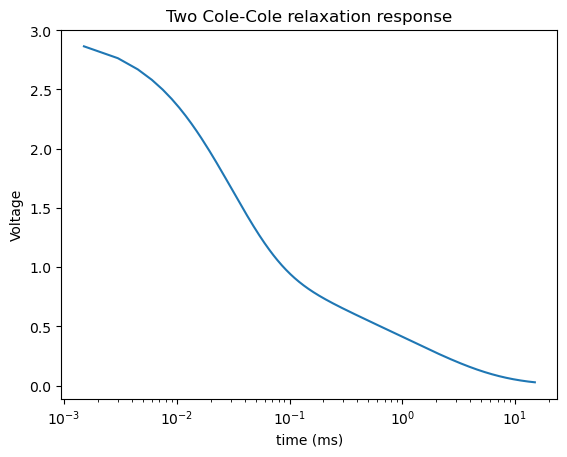

In [4]:
plt.plot(t*1000, V_out)
plt.xscale('log')
plt.xlabel('time (ms)')
plt.ylabel('Voltage')
plt.title('Two Cole-Cole relaxation response')